# Web scraping das eleições 2026 — 1º turno

**Atividade assistida · Métodos Estatísticos em Ciência de Dados · FAETERJ**

Coleta, limpeza e análise dos resultados do 1º turno de 4 de outubro de 2026 para os quatro cargos pedidos:
**Presidente, Senador, Deputado Federal e Deputado Estadual** (no DF, Deputado Distrital).

Roteiro do notebook, seguindo os passos da aula:

| Passo | O que é feito |
|---|---|
| 0 | Como a página entrega os dados e qual fonte usar |
| 1–2 | Encontrar o JSON e reproduzir a requisição em Python (com cache e pausa) |
| 3 | Coletar os 4 cargos nas 27 UFs |
| 4 | Do JSON ao DataFrame: limpeza, checagens e validação dos totais com o TSE |
| 5 | Aplicar os métodos da Parte 1: tendência central, dispersão, outliers, moda, correlação e PCA |
| — | Um gráfico por cargo, PCA com leitura dos loadings e parágrafo sobre limites |

Todos os arquivos gerados ficam em `dados/` (CSVs) e `figuras/` (PNGs). As respostas brutas do TSE ficam em `cache/`,
o que permite refazer a análise sem acessar o servidor de novo.

## Passo 0 · Como a página entrega os dados?

Na página de apuração da CNN Brasil, `requests.get(url).text` devolve só o aviso *"Carregando dados da apuração..."*:
os números chegam depois, por JavaScript, e `requests` + BeautifulSoup não enxergam o que o JavaScript desenha.

Ao abrir o DevTools (F12 → Network → Fetch/XHR) em qualquer página de apuração, inclusive no próprio
[resultados.tse.jus.br](https://resultados.tse.jus.br), as requisições que trazem os votos apontam para arquivos JSON
do **TSE**. Os portais apenas reproduzem esses arquivos. Por isso usamos direto a **fonte primária**, que é o caminho
mais estável indicado na aula.

**Regras do site.** O domínio `resultados.tse.jus.br` não publica `robots.txt` (a URL responde erro 503). Os arquivos
são dados públicos oficiais, servidos por CDN e feitos para serem consumidos por aplicativos e pela imprensa. Mesmo assim,
seguimos as boas práticas da aula: **cache local** (cada arquivo é baixado uma única vez), **pausa de 1,5 s** entre
chamadas, `User-Agent` identificando a aula e nenhum laço infinito. Também registramos a **data e a hora** de cada
arquivo, para citar a fonte.

In [1]:
import json
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

BASE = "https://resultados.tse.jus.br/oficial"
HEADERS = {"User-Agent": "aula-ciencia-de-dados (FAETERJ)"}
PAUSA = 1.5  # segundos entre chamadas à rede

CACHE, DADOS, FIGS = Path("cache"), Path("dados"), Path("figuras")
for pasta in (CACHE, DADOS, FIGS):
    pasta.mkdir(exist_ok=True)

UFS = ["ac", "al", "am", "ap", "ba", "ce", "df", "es", "go", "ma", "mg", "ms", "mt", "pa",
       "pb", "pe", "pi", "pr", "rj", "rn", "ro", "rr", "rs", "sc", "se", "sp", "to"]

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Passos 1 e 2 · Encontrar o JSON e reproduzir a requisição

A função `baixar` é o mesmo código do slide do passo 2 (`requests.get` com `timeout`, `raise_for_status` e pausa),
com um cache em disco: se o arquivo já foi salvo, ele é lido do disco e o servidor não é chamado. Cada download
fica registrado em `log_coleta`, com URL, status e horário.

In [2]:
log_coleta = []


def baixar(caminho):
    """Devolve o JSON de BASE/caminho, usando o cache local quando o arquivo já foi baixado."""
    arquivo = CACHE / caminho.replace("/", "_")
    if arquivo.exists():
        return json.loads(arquivo.read_text(encoding="utf-8"))

    url = f"{BASE}/{caminho}"
    resp = requests.get(url, headers=HEADERS, timeout=60)
    log_coleta.append({"url": url, "status": resp.status_code,
                       "coletado_em": datetime.now().isoformat(timespec="seconds")})
    resp.raise_for_status()  # falha clara se der erro HTTP (403/404/429...)
    arquivo.write_bytes(resp.content)
    time.sleep(PAUSA)
    return resp.json()

O primeiro arquivo que a página do TSE carrega é a configuração `comum/config/ele-c.json`. Ele lista os pleitos e,
para cada eleição, o código e os cargos. Assim não precisamos "chutar" os códigos de 2026: eles saem da própria fonte.

In [3]:
config = baixar("comum/config/ele-c.json")
pleito = next(p for p in config["pl"] if p["c"] == "ele2026")

eleicoes = pd.DataFrame(
    [{"cd_eleicao": e["cd"], "nome": e["nm"], "turno": e["t"],
      "cargos": ", ".join(f'{c["cd"]}={c["ds"]}' for a in e["abr"] for c in a["cp"])}
     for e in pleito["e"]]
)
print("Pleito:", pleito["c"], "| data:", pleito["dt"])
eleicoes

Pleito: ele2026 | data: 04/10/2026


,cd_eleicao,nome,turno,cargos
0,6257,Eleição Ordinária Federal - 2026 1º Turno,1,1=Presidente
1,6259,Eleição Ordinária Estadual - 2026 1º Turno,1,"3=Governador, 5=Senador, 6=Deputado Federal, 7..."
2,6261,Eleição Ordinária Municipal - 2026 - 04/10/202...,1,25=Conselheiro Distrital


Os códigos que interessam são **6257** (eleição federal: Presidente, cargo 1) e **6259** (eleição estadual:
Senador = 5, Deputado Federal = 6, Deputado Estadual = 7 e Deputado Distrital = 8).

Pelo DevTools, o arquivo de resultados de um cargo numa abrangência segue o padrão

```
ele2026/<eleicao>/dados/<uf>/<uf>-c<cargo com 4 dígitos>-e<eleicao com 6 dígitos>-u.json
```

Um teste com o Presidente no Brasil inteiro, imprimindo as chaves antes de tratar (como pede o passo 2):

In [4]:
ELEICAO = {"presidente": 6257, "estadual": 6259}


def caminho_resultado(eleicao, cargo, uf):
    return f"ele2026/{eleicao}/dados/{uf}/{uf}-c{cargo:04d}-e{eleicao:06d}-u.json"


teste = baixar(caminho_resultado(ELEICAO["presidente"], 1, "br"))
print(type(teste), list(teste)[:20])
print("Totalização do TSE em:", teste["dg"], teste["hg"], "| apuração finalizada?", teste["tf"])
print("Chaves de um candidato:", list(teste["carg"][0]["agr"][0]["par"][0]["cand"][0]))

<class 'dict'> ['ele', 't', 'f', 'sup', 'tpabr', 'cdabr', 'dg', 'hg', 'idg', 'dt', 'ht', 'dv', 'tf', 'and', 'esae', 'mnae', 'carg', 's', 'e', 'v']
Totalização do TSE em: 05/10/2026 12:51:47 | apuração finalizada? s
Chaves de um candidato: ['n', 'sqcand', 'nm', 'nmu', 'dt', 'dvt', 'seq', 'e', 'st', 'vap', 'pvap', 'pvapn', 'vs']


Mapa das chaves que vamos usar (estrutura `carg → agr → par → cand`, ou seja, cargo → coligação/federação → partido → candidato):

| Chave | Significado | Chave | Significado |
|---|---|---|---|
| `nmu` / `nm` | nome de urna / nome completo | `vap` | votos apurados do candidato |
| `n` | número do candidato | `pvapn` | % dos votos válidos, **com vírgula decimal** |
| `sg` (partido) | sigla do partido | `st` | situação (Eleito, 2º turno, Suplente...) |
| `dvt` | destinação do voto (Válido, Anulado sub judice) | `v.vnom` | total de votos nominais válidos (para validar) |
| `e.te`, `e.c`, `e.a` | eleitorado, comparecimento, abstenção | `v.vb`, `v.tvn` | brancos, nulos |

## Passo 3 · Os quatro cargos do 1º turno

Estratégia do slide: **laço sobre as 27 UFs**, pausa entre as chamadas e um DataFrame por cargo.

- **Presidente**: além das 27 UFs, baixamos `br` (total nacional) e `zz` (votos no exterior). Assim conferimos que
  27 UFs + exterior = Brasil.
- **Senador**: 27 UFs. Em 2026, cada eleitor deu **dois votos** (dois terços do Senado em disputa).
- **Deputado Federal**: 27 UFs.
- **Deputado Estadual**: 26 UFs com o cargo 7. No DF, o cargo equivalente é **Deputado Distrital** (código 8).

Na primeira execução são 111 arquivos (com a configuração), cerca de 4 minutos por causa da pausa. Nas seguintes, tudo vem do cache.

In [5]:
PLANO = {
    "presidente":        [(ELEICAO["presidente"], 1, uf) for uf in ["br", "zz"] + UFS],
    "senador":           [(ELEICAO["estadual"], 5, uf) for uf in UFS],
    "deputado_federal":  [(ELEICAO["estadual"], 6, uf) for uf in UFS],
    "deputado_estadual": [(ELEICAO["estadual"], 8 if uf == "df" else 7, uf) for uf in UFS],
}

brutos = {cargo: {uf: baixar(caminho_resultado(ele, cd, uf)) for ele, cd, uf in itens}
          for cargo, itens in PLANO.items()}

print({cargo: len(arqs) for cargo, arqs in brutos.items()})
print("Downloads feitos nesta execução:", len(log_coleta), "(o resto veio do cache)")

{'presidente': 29, 'senador': 27, 'deputado_federal': 27, 'deputado_estadual': 27}
Downloads feitos nesta execução: 0 (o resto veio do cache)


## Passo 4 · Do JSON ao DataFrame

Duas tabelas saem de cada arquivo:

1. **candidatos**: uma linha por candidato, com as colunas padronizadas pedidas no slide (`cargo, uf, candidato, partido, votos`)
   e mais algumas úteis (número, situação, % de válidos);
2. **totais**: uma linha por cargo e UF, com eleitorado, comparecimento, brancos, nulos e o total oficial de votos nominais.
   Os totais servem para validar a coleta.

Tudo no JSON vem como **texto**, e os percentuais usam **vírgula decimal** (`"47,027772356"`). A conversão
(`to_numeric`, troca de vírgula por ponto) é feita explicitamente.

In [6]:
def para_numero(serie):
    """Texto do TSE -> número: troca a vírgula decimal por ponto e converte."""
    return pd.to_numeric(serie.astype(str).str.replace(",", ".", regex=False), errors="coerce")


def extrair_candidatos(dados, cargo):
    linhas = []
    for c in dados["carg"]:
        for agr in c["agr"]:
            for par in agr["par"]:
                for cand in par["cand"]:
                    linhas.append({
                        "cargo": cargo,
                        "uf": dados["cdabr"].upper(),
                        "numero": cand["n"],
                        "candidato": cand["nmu"],
                        "nome_completo": cand["nm"],
                        "partido": par["sg"],
                        "agremiacao": agr.get("com", ""),
                        "votos": cand["vap"],
                        "pct_validos": cand["pvapn"],
                        "situacao": cand["st"],
                        "destinacao": cand["dvt"],
                    })
    return linhas


def extrair_totais(dados, cargo):
    e, v = dados["e"], dados["v"]
    return {
        "cargo": cargo, "uf": dados["cdabr"].upper(),
        "vagas": dados["carg"][0]["nv"],
        "eleitorado": e["te"], "comparecimento": e["c"], "abstencao": e["a"],
        "votos_nominais": v["vnom"], "votos_legenda": v.get("vl", "0"),
        "anulados_sub_judice": v["vansj"], "brancos": v["vb"], "nulos": v["tvn"],
        "totalizado_em": f'{dados["dg"]} {dados["hg"]}',
    }


cand = pd.DataFrame([linha for cargo, arqs in brutos.items()
                     for d in arqs.values() for linha in extrair_candidatos(d, cargo)])
tot = pd.DataFrame([extrair_totais(d, cargo) for cargo, arqs in brutos.items() for d in arqs.values()])

print("Antes da conversão:", cand[["votos", "pct_validos"]].dtypes.to_dict())
cand["votos"] = para_numero(cand["votos"]).astype("Int64")
cand["pct_validos"] = para_numero(cand["pct_validos"])
num_cols = ["vagas", "eleitorado", "comparecimento", "abstencao", "votos_nominais",
            "votos_legenda", "anulados_sub_judice", "brancos", "nulos"]
tot[num_cols] = tot[num_cols].apply(para_numero).astype("Int64")
print("Depois da conversão:", cand[["votos", "pct_validos"]].dtypes.to_dict())
cand.head()

Antes da conversão: {'votos': <StringDtype(na_value=nan)>, 'pct_validos': <StringDtype(na_value=nan)>}
Depois da conversão: {'votos': Int64Dtype(), 'pct_validos': dtype('float64')}


,cargo,uf,numero,candidato,nome_completo,partido,agremiacao,votos,pct_validos,situacao,destinacao
0,presidente,BR,22,FLAVIO BOLSONARO,FLAVIO NANTES BOLSONARO,PL,PL,56104503,47.027772,2º turno,Válido
1,presidente,BR,55,RONALDO CAIADO,RONALDO RAMOS CAIADO,PSD,PSD,2605148,2.183680,Não eleito,Válido
2,presidente,BR,13,LULA,LUIZ INÁCIO LULA DA SILVA,PT,PSB / PDT / PCDOB / PT / PV / PSOL / REDE,53879538,45.162768,2º turno,Válido
3,presidente,BR,27,CLARIANA BARAO,CLARIANA ZACARKIM BARAO,DC,DC,40043,0.033565,Não eleito,Válido
4,presidente,BR,21,EDMILSON COSTA,EDMILSON SILVA COSTA,PCB,PCB,22693,0.019022,Não eleito,Válido


### Checagens do slide do passo 4

1. Votos são números? Há algum valor que não converteu?
2. Há duplicatas?
3. A **soma dos votos dos candidatos confere com o total do TSE**? Comparamos a soma dos candidatos com destinação
   "Válido" com o campo oficial `vnom` (votos nominais válidos), cargo a cargo e UF a UF.
4. No Presidente: 27 UFs + exterior = total nacional?

In [7]:
print("Votos que não converteram:", cand["votos"].isna().sum(), "| % que não converteram:", cand["pct_validos"].isna().sum())

chave = ["cargo", "uf", "numero"]
print("Linhas duplicadas:", cand.duplicated().sum(), "| chaves duplicadas (cargo, uf, número):", cand.duplicated(chave).sum())
cand = cand.drop_duplicates()

print("\nDestinação dos votos:")
print(cand.groupby(["cargo", "destinacao"]).size().unstack(fill_value=0))

Votos que não converteram: 0 | % que não converteram: 0
Linhas duplicadas: 0 | chaves duplicadas (cargo, uf, número): 0

Destinação dos votos:
destinacao         Anulado  Anulado sub judice  Válido
cargo                                                 
deputado_estadual        4                 236   10847
deputado_federal        16                 195    7051
presidente               0                   0     348
senador                  5                  19     277


In [8]:
soma_validos = (cand[cand["destinacao"] == "Válido"]
                .groupby(["cargo", "uf"])["votos"].sum().rename("soma_candidatos"))
validacao = tot.set_index(["cargo", "uf"])[["votos_nominais"]].join(soma_validos)
validacao["diferenca"] = validacao["soma_candidatos"] - validacao["votos_nominais"]

print("Pares cargo × UF conferidos:", len(validacao))
print("Pares com diferença diferente de zero:", (validacao["diferenca"] != 0).sum())
validacao.groupby("cargo")[["votos_nominais", "soma_candidatos", "diferenca"]].sum()

Pares cargo × UF conferidos: 110
Pares com diferença diferente de zero: 0


,votos_nominais,soma_candidatos,diferenca
cargo,,,
deputado_estadual,105468464,105468464,0
deputado_federal,110246229,110246229,0
presidente,238601576,238601576,0
senador,207038240,207038240,0


In [9]:
pres_tot = tot[tot["cargo"] == "presidente"].set_index("uf")["votos_nominais"]
soma_ufs = pres_tot.drop(["BR", "ZZ"]).sum()
print(f"Presidente · soma das 27 UFs: {soma_ufs:>12,}")
print(f"Presidente · exterior (ZZ):   {pres_tot['ZZ']:>12,}")
print(f"Presidente · UFs + exterior:  {soma_ufs + pres_tot['ZZ']:>12,}")
print(f"Presidente · total BR do TSE: {pres_tot['BR']:>12,}")
print("Confere?", soma_ufs + pres_tot["ZZ"] == pres_tot["BR"])
print("\nHorário de totalização dos arquivos coletados:", sorted(tot["totalizado_em"].unique())[:3], "...",
      sorted(tot["totalizado_em"].unique())[-1])

Presidente · soma das 27 UFs:  118,969,906
Presidente · exterior (ZZ):        330,882
Presidente · UFs + exterior:   119,300,788
Presidente · total BR do TSE:  119,300,788
Confere? True

Horário de totalização dos arquivos coletados: ['04/10/2026 20:51:22', '04/10/2026 20:57:09', '04/10/2026 20:57:10'] ... 15/10/2026 19:12:00


A soma dos candidatos bate **exatamente** com o total oficial em todos os pares cargo × UF, e no Presidente as 27 UFs
mais o exterior somam o total nacional. A coleta está completa.

Além dos válidos, há votos com destinação "Anulado" (candidato com registro indeferido) e "Anulado sub judice"
(registro ainda em discussão na Justiça Eleitoral). Eles ficam no CSV, identificados pela coluna `destinacao`, mas
**não entram** nos votos válidos nem nas análises abaixo.

Agora salvamos **um CSV por cargo**, mais a tabela de totais e o registro da coleta:

In [10]:
for cargo, df in cand.groupby("cargo"):
    df.sort_values(["uf", "votos"], ascending=[True, False]).to_csv(DADOS / f"{cargo}_1t.csv", index=False)
tot.to_csv(DADOS / "totais_por_uf_1t.csv", index=False)
if log_coleta:  # só grava o registro quando houve download (numa execução só com cache, não há o que registrar)
    pd.DataFrame(log_coleta).to_csv(DADOS / f"log_coleta_{datetime.now():%Y%m%d_%H%M%S}.csv", index=False)

sorted(p.name for p in DADOS.glob("*.csv"))

['deputado_estadual_1t.csv',
 'deputado_federal_1t.csv',
 'log_coleta_20261016_004452.csv',
 'pca_loadings.csv',
 'pca_scores_ufs.csv',
 'presidente_1t.csv',
 'resumo_estatistico_por_cargo.csv',
 'senador_1t.csv',
 'totais_por_uf_1t.csv']

## Passo 5 · Aplicar os métodos da aula

A partir daqui, usamos só os votos **válidos** e, no Presidente, só as 27 UFs (o total `BR` e o exterior `ZZ` ficam
de fora para não contar votos duas vezes).

In [11]:
val = cand[cand["destinacao"] == "Válido"].copy()
val["votos"] = val["votos"].astype(float)
pres_uf = val[(val["cargo"] == "presidente") & ~val["uf"].isin(["BR", "ZZ"])]
pres_br = val[(val["cargo"] == "presidente") & (val["uf"] == "BR")]

ROTULO = {"presidente": "Presidente", "senador": "Senador",
          "deputado_federal": "Deputado Federal", "deputado_estadual": "Deputado Estadual/Distrital"}

### Regra de ouro: olhar os dados antes de escolher a medida

Antes de calcular qualquer resumo, um histograma dos votos por candidato em cada cargo. Usamos o eixo em escala log
porque os votos vão de dezenas a milhões.

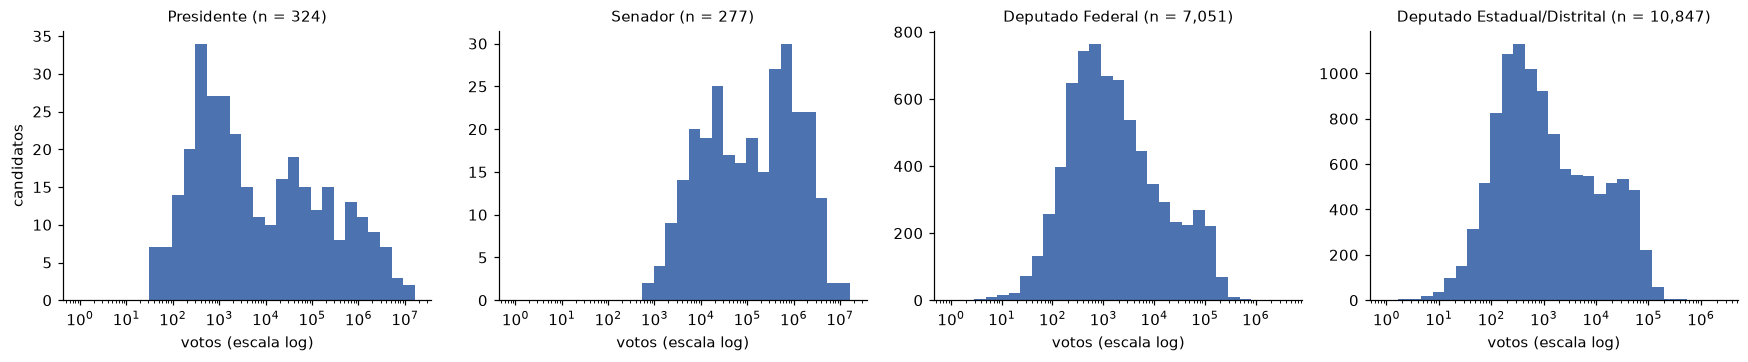

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, (cargo, df) in zip(axes, [("presidente", pres_uf)] +
                            [(c, val[val["cargo"] == c]) for c in ["senador", "deputado_federal", "deputado_estadual"]]):
    v = df["votos"][df["votos"] > 0]
    ax.hist(v, bins=np.logspace(0, np.log10(v.max()) + 0.1, 30), color="#4C72B0")
    ax.set_xscale("log")
    ax.set_title(f"{ROTULO[cargo]} (n = {len(df):,})", fontsize=10)
    ax.set_xlabel("votos (escala log)")
axes[0].set_ylabel("candidatos")
plt.tight_layout()
plt.show()

### Tendência central, dispersão e outliers por cargo

Para cada cargo, calculamos média, mediana, desvio padrão (amostral, `n − 1`, o padrão do pandas), coeficiente de
variação, quartis, IQR e a regra de Tukey (outlier acima de Q3 + 1,5 × IQR).

No Presidente, a unidade de análise é o candidato em cada UF (12 candidatos × 27 UFs). Nos demais cargos, é o candidato
na sua UF.

In [13]:
def resumo(votos):
    q1, q3 = np.percentile(votos, [25, 75])
    iqr = q3 - q1
    lim_sup = q3 + 1.5 * iqr
    return pd.Series({
        "candidatos": len(votos), "média": votos.mean(), "mediana": votos.median(),
        "desvio_padrão": votos.std(), "CV_%": 100 * votos.std() / votos.mean(),
        "Q1": q1, "Q3": q3, "IQR": iqr, "limite_Tukey": lim_sup,
        "outliers": int((votos > lim_sup).sum()),
        "%_outliers": 100 * (votos > lim_sup).mean(),
        "média/mediana": votos.mean() / votos.median(),
    })


tabela = pd.DataFrame({ROTULO["presidente"]: resumo(pres_uf["votos"])} |
                      {ROTULO[c]: resumo(val.loc[val["cargo"] == c, "votos"])
                       for c in ["senador", "deputado_federal", "deputado_estadual"]}).T
tabela.to_csv(DADOS / "resumo_estatistico_por_cargo.csv")
tabela.style.format("{:,.1f}").format("{:,.0f}", subset=["candidatos", "outliers"])

,candidatos,média,mediana,desvio_padrão,CV_%,Q1,Q3,IQR,limite_Tukey,outliers,%_outliers,média/mediana
Presidente,324,"367,191.1","3,731.5","1,215,158.7",330.9,507.0,"85,273.2","84,766.2","212,422.6",59,18.2,98.4
Senador,277,"747,430.5","138,269.0","1,548,978.2",207.2,"17,444.0","856,045.0","838,601.0","2,113,946.5",26,9.4,5.4
Deputado Federal,"7,051","15,635.5","1,270.0","67,459.8",431.5,368.0,"6,453.5","6,085.5","15,581.8","1,192",16.9,12.3
Deputado Estadual/Distrital,"10,847","9,723.3",813.0,"30,314.6",311.8,229.0,"6,318.0","6,089.0","15,451.5","1,824",16.8,12.0


In [14]:
dep = val[val["cargo"] == "deputado_federal"]
print(f"Deputado Federal · média {dep['votos'].mean():,.0f} · mediana {dep['votos'].median():,.0f} votos")
print(f"Desvio padrão amostral (pandas, n−1): {dep['votos'].std():,.1f}")
print(f"Desvio padrão populacional (np.std, n): {np.std(dep['votos']):,.1f}")
print(f"np.std com ddof=1:                   {np.std(dep['votos'], ddof=1):,.1f}")

eleitos_dep = dep[dep["situacao"].str.startswith("Eleito")]
print(f"\nEleitos: {len(eleitos_dep)} de {len(dep):,} candidatos ({100*len(eleitos_dep)/len(dep):.1f}%)")
print(f"Votos que os eleitos receberam: {100*eleitos_dep['votos'].sum()/dep['votos'].sum():.1f}% do total nominal")

Deputado Federal · média 15,636 · mediana 1,270 votos
Desvio padrão amostral (pandas, n−1): 67,459.8
Desvio padrão populacional (np.std, n): 67,455.0
np.std com ddof=1:                   67,459.8

Eleitos: 505 de 7,051 candidatos (7.2%)
Votos que os eleitos receberam: 63.0% do total nominal


**Os outliers são erro?** Não. A aula avisa: *outlier não é erro automático, pode ser um puxador de votos real*.
Os candidatos a Deputado Federal mais acima do limite de Tukey, e o z-score de cada um:

In [15]:
dep = dep.assign(z=(dep["votos"] - dep["votos"].mean()) / dep["votos"].std())
lim = tabela.loc[ROTULO["deputado_federal"], "limite_Tukey"]
print(f"Limite de Tukey: {lim:,.0f} votos · candidatos com |z| > 3: {(dep['z'].abs() > 3).sum()}")
dep.nlargest(10, "votos")[["uf", "candidato", "partido", "votos", "z", "situacao"]]

Limite de Tukey: 15,582 votos · candidatos com |z| > 3: 41


,uf,candidato,partido,votos,z,situacao
2638,MG,NIKOLAS FERREIRA,PL,3119318.0,46.007880,Eleito por QP
7143,SP,LUCAS PAVANATO,PL,3038438.0,44.808943,Eleito por QP
7740,SP,ERIKA HILTON,PSOL,1596472.0,23.433755,Eleito por QP
1709,CE,ANDRÉ FERNANDES,PL,684372.0,9.913110,Eleito por QP
7745,SP,SÂMIA BOMFIM,PSOL,583107.0,8.411994,Eleito por QP
6508,SC,JULIA ZANATTA,PL,560223.0,8.072770,Eleito por QP
2711,MG,ANA ELISA,PT,524219.0,7.539059,Eleito por QP
6789,SP,KIM KATAGUIRI,MISSÃO,520071.0,7.477571,Eleito por QP
6842,SP,TABATA AMARAL,PSB,476383.0,6.829956,Eleito por QP
4796,PR,JEFFREY CHIQUINI,NOVO,425399.0,6.074187,Eleito por QP


### Moda: partido mais votado por UF

A moda serve para variáveis **categóricas**. Para cada UF, achamos o partido com mais votos nominais para
Deputado Federal. Depois, a moda dessa lista de 27 partidos diz qual partido "ganha" em mais estados.
Fazemos o mesmo para as cadeiras conquistadas.

In [16]:
votos_partido = (val[val["cargo"] == "deputado_federal"]
                 .groupby(["uf", "partido"])["votos"].sum().reset_index())
mais_votado = votos_partido.loc[votos_partido.groupby("uf")["votos"].idxmax()].set_index("uf")

print("Partido mais votado (Dep. Federal) em cada UF:")
print(mais_votado["partido"].to_dict())
print("\nModa entre as 27 UFs:", list(mais_votado["partido"].mode()))
print(mais_votado["partido"].value_counts().head(6).to_string())

eleitos = cand[cand["situacao"].str.startswith("Eleito")]
cadeiras = (eleitos[eleitos["cargo"].isin(["senador", "deputado_federal"])]
            .groupby(["cargo", "partido"]).size().unstack(0, fill_value=0)
            .sort_values("deputado_federal", ascending=False))
print("\nTotal de eleitos:", cadeiras.sum().to_dict())
cadeiras.head(10)

Partido mais votado (Dep. Federal) em cada UF:
{'AC': 'PP', 'AL': 'PP', 'AM': 'MDB', 'AP': 'UNIÃO', 'BA': 'PT', 'CE': 'PL', 'DF': 'PL', 'ES': 'PL', 'GO': 'PL', 'MA': 'MDB', 'MG': 'PL', 'MS': 'PL', 'MT': 'PL', 'PA': 'MDB', 'PB': 'REPUBLICANOS', 'PE': 'PSB', 'PI': 'PT', 'PR': 'NOVO', 'RJ': 'PL', 'RN': 'PL', 'RO': 'PL', 'RR': 'REPUBLICANOS', 'RS': 'PL', 'SC': 'PL', 'SE': 'PSD', 'SP': 'PL', 'TO': 'REPUBLICANOS'}

Moda entre as 27 UFs: ['PL']
partido
PL              13
MDB              3
REPUBLICANOS     3
PP               2
PT               2
UNIÃO            1

Total de eleitos: {'deputado_federal': 505, 'senador': 54}


cargo,deputado_federal,senador
partido,,
PL,118,19
PT,70,6
UNIÃO,44,3
PSD,42,2
PP,41,3
REPUBLICANOS,41,2
MDB,36,7
PODE,25,2
PSB,15,3


### Correlação: candidatos a Presidente que andam juntos entre as UFs

Para cada UF, montamos o percentual de votos válidos de cada candidato a Presidente. A pergunta é se, nas UFs em que
um candidato vai bem, outro também vai bem (correlação positiva) ou vai mal (negativa).

Usamos só os candidatos com pelo menos **1% dos votos válidos no país**. Os demais têm percentuais muito pequenos
(abaixo de 0,3%) e quase só ruído entre as UFs. Calculamos Pearson e Spearman lado a lado: o percentual por UF é
assimétrico e tem UFs extremas, e o Spearman, por usar só a ordem, é menos sensível a elas.

In [17]:
principais = pres_br.loc[pres_br["pct_validos"] >= 1, "candidato"].tolist()
pct = pres_uf[pres_uf["candidato"].isin(principais)][["uf", "candidato", "pct_validos"]]
X = pct.pivot(index="uf", columns="candidato", values="pct_validos")[principais]
NOME_CURTO = {"FLAVIO BOLSONARO": "Flávio Bolsonaro", "ESCRITOR AUGUSTO CURY": "Augusto Cury"}
X.columns = [NOME_CURTO.get(c, c.title()) for c in X.columns]

print("Candidatos usados:", list(X.columns))
print("Matriz X:", X.shape, "(UFs × candidatos)\n")
print(X.describe().round(2).to_string())

Candidatos usados: ['Flávio Bolsonaro', 'Ronaldo Caiado', 'Lula', 'Augusto Cury', 'Renan Santos']
Matriz X: (27, 5) (UFs × candidatos)

       Flávio Bolsonaro  Ronaldo Caiado   Lula  Augusto Cury  Renan Santos
count             27.00           27.00  27.00         27.00         27.00
mean              47.86            2.09  45.00          2.72          1.97
std               13.68            2.20  14.70          0.55          0.52
min               24.09            0.78  22.86          1.41          1.37
25%               33.92            1.18  32.94          2.44          1.55
50%               50.44            1.74  43.33          2.64          1.73
75%               57.12            2.04  60.53          2.96          2.31
max               71.06           12.33  70.99          4.10          3.23


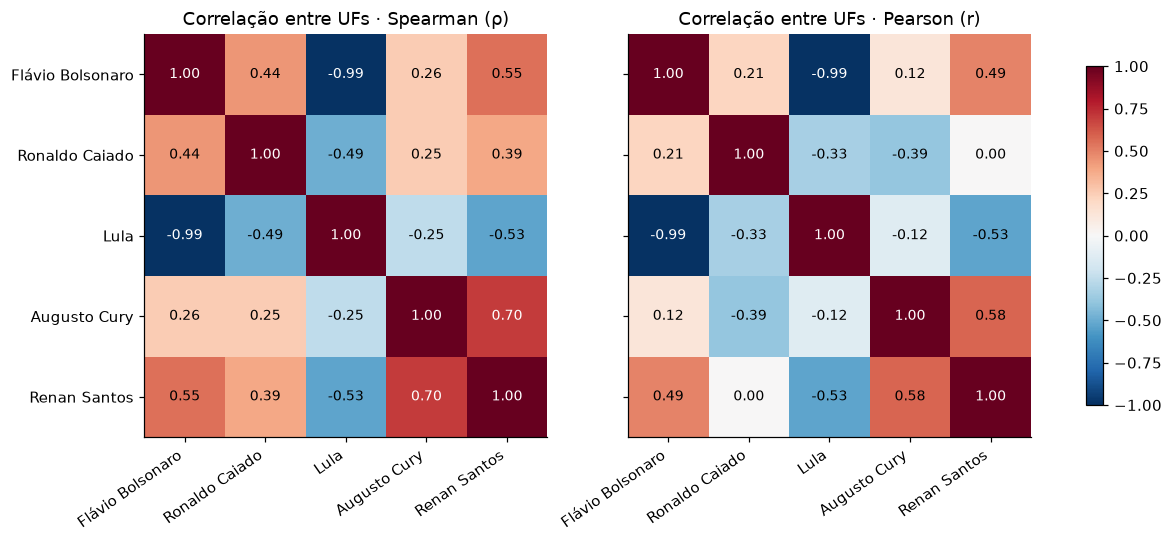

Maior diferença: Augusto Cury × Ronaldo Caiado · Spearman 0.25 · Pearson -0.39
    Flávio Bolsonaro  Ronaldo Caiado   Lula  Augusto Cury  Renan Santos
uf                                                                     
GO              53.6           12.33  31.06          1.41          1.41
Sem GO · Pearson Augusto Cury × Ronaldo Caiado: 0.19


In [18]:
spearman = X.corr(method="spearman")
pearson = X.corr(method="pearson")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (nome, m) in zip(axes, [("Spearman (ρ)", spearman), ("Pearson (r)", pearson)]):
    im = ax.imshow(m, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(m)), m.columns, rotation=35, ha="right")
    ax.set_yticks(range(len(m)), m.index)
    ax.tick_params(labelleft=(ax is axes[0]))
    for i in range(len(m)):
        for j in range(len(m)):
            ax.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(m.iloc[i, j]) > 0.6 else "black")
    ax.set_title(f"Correlação entre UFs · {nome}")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.savefig(FIGS / "correlacao_presidente_ufs.png", bbox_inches="tight")
plt.show()

dif = (spearman - pearson).abs().stack()
a, b = dif[dif.index.get_level_values(0) < dif.index.get_level_values(1)].idxmax()
print(f"Maior diferença: {a} × {b} · Spearman {spearman.loc[a, b]:.2f} · Pearson {pearson.loc[a, b]:.2f}")
print(X.loc[["GO"]].round(2).to_string())
print(f"Sem GO · Pearson {a} × {b}: {X.drop('GO').corr().loc[a, b]:.2f}")

**Leitura.**

- **Flávio × Lula: −0,99 nas duas medidas.** Os dois somam entre 85% (GO) e 95% (AL) dos válidos, então onde um sobe o outro cai quase na mesma medida. Parte disso é mecânica: percentuais que somam 100% são negativamente correlacionados por construção.
- **Renan Santos anda com Flávio (ρ = 0,55) e contra Lula (ρ = −0,53).** **Augusto Cury e Renan Santos andam juntos (ρ = 0,70)**: os dois vão melhor nas mesmas UFs (SP, SC, PR, RS, AP), e pior em boa parte do Nordeste e do Centro-Oeste.
- **Onde Pearson e Spearman discordam, há um outlier.** Em Caiado × Cury, Spearman dá +0,25 e Pearson dá −0,39. A diferença vem de **Goiás**: Caiado, ex-governador do estado, teve 12,33% lá (o resto das UFs fica entre 0,8% e 4,8%), e Cury teve em GO o menor valor do país (1,41%). Sem GO, o Pearson passa para +0,19, perto do Spearman. Uma única UF inverteu o sinal do Pearson, o que mostra na prática o cuidado do slide (*sensível a outliers*).
- Lembrete: é correlação **entre UFs**, não entre eleitores (falácia ecológica), e correlação não é causalidade.

## Um gráfico por cargo

### Presidente · resultado nacional

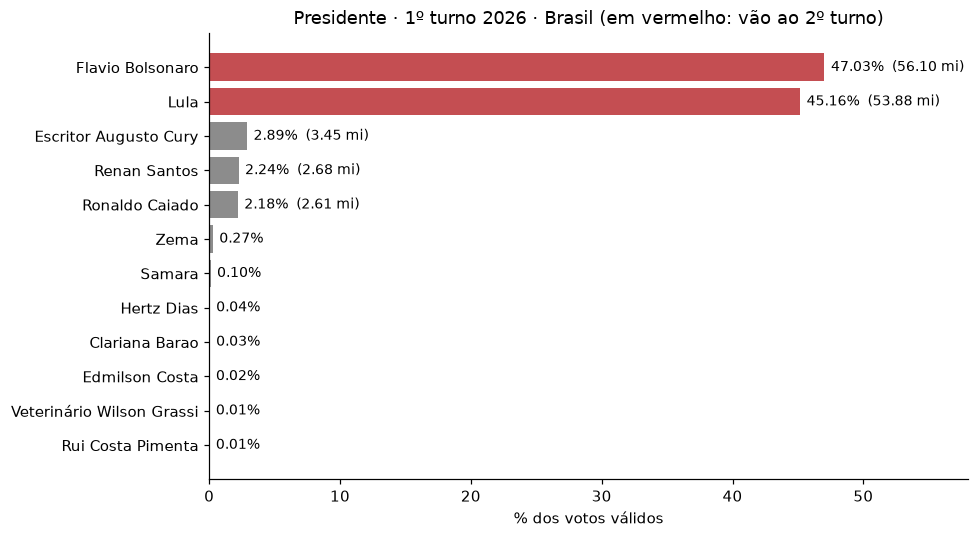

In [19]:
br = pres_br.sort_values("votos")
cores = ["#C44E52" if s == "2º turno" else "#8C8C8C" for s in br["situacao"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(br["candidato"].str.title(), br["pct_validos"], color=cores)
for y, (p, v) in enumerate(zip(br["pct_validos"], br["votos"])):
    ax.text(p + 0.5, y, f"{p:.2f}%  ({v/1e6:.2f} mi)" if p >= 1 else f"{p:.2f}%", va="center", fontsize=9)
ax.set_xlabel("% dos votos válidos")
ax.set_xlim(0, 58)
ax.set_title("Presidente · 1º turno 2026 · Brasil (em vermelho: vão ao 2º turno)")
plt.tight_layout()
plt.savefig(FIGS / "grafico_presidente.png", bbox_inches="tight")
plt.show()

### Senador · cadeiras conquistadas por partido

Somar votos de Senador entre UFs é enganoso: cada eleitor deu dois votos e o número de candidatos varia por UF.
O que se compara entre partidos são as **cadeiras**. Em cada UF, os dois mais votados foram eleitos.

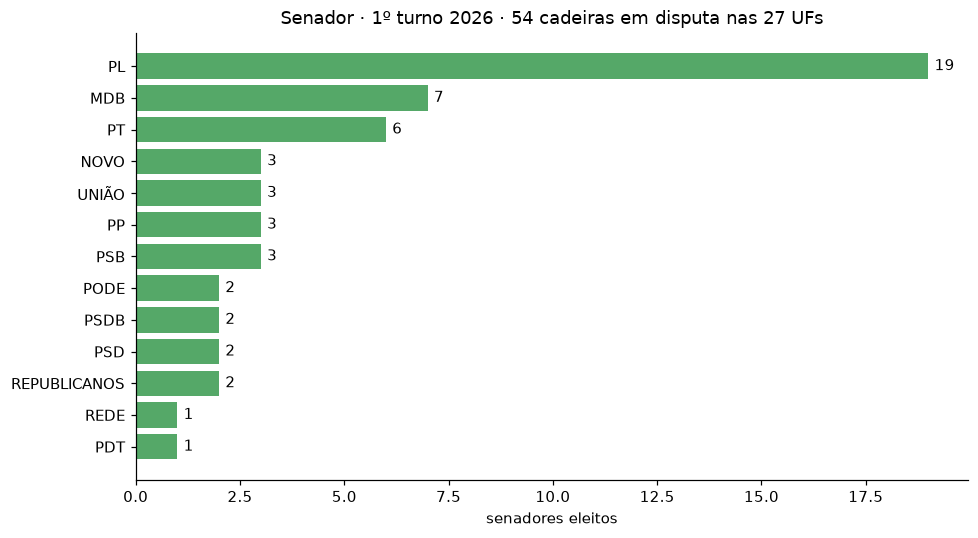

In [20]:
sen_eleitos = eleitos[eleitos["cargo"] == "senador"]
contagem = sen_eleitos["partido"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(contagem.index, contagem.values, color="#55A868")
for y, n in enumerate(contagem.values):
    ax.text(n + 0.15, y, str(n), va="center")
ax.set_xlabel("senadores eleitos")
ax.set_title(f"Senador · 1º turno 2026 · {len(sen_eleitos)} cadeiras em disputa nas 27 UFs")
plt.tight_layout()
plt.savefig(FIGS / "grafico_senador.png", bbox_inches="tight")
plt.show()

### Deputado Federal · distribuição dos votos por candidato

O histograma mostra a assimetria que justifica preferir a mediana. Mesmo em escala log, média e mediana ficam
muito distantes.

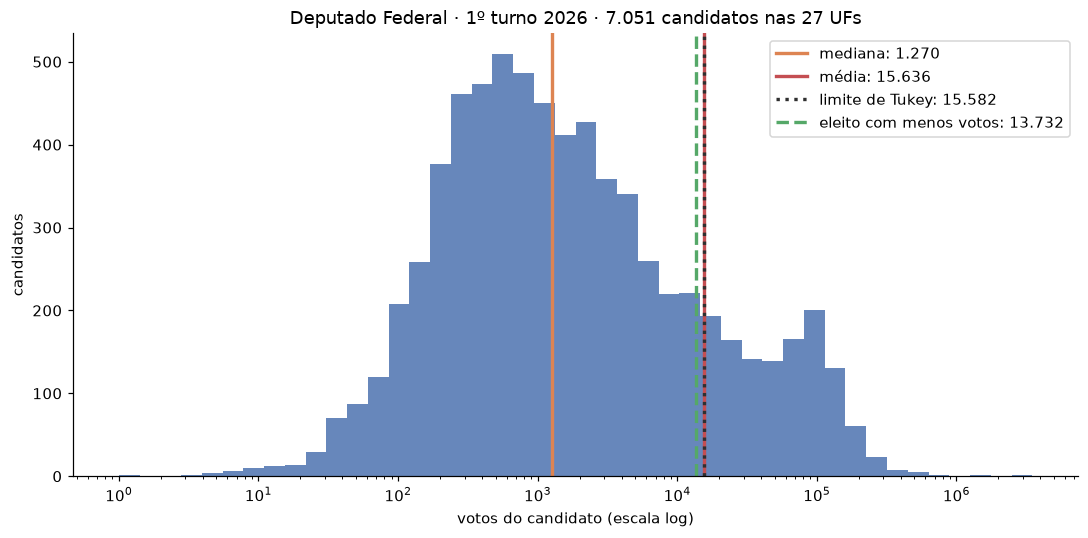

In [21]:
dep = val[val["cargo"] == "deputado_federal"]
v = dep["votos"][dep["votos"] > 0]
corte = dep.loc[dep["situacao"].str.startswith("Eleito"), "votos"].min()  # eleito com menos votos

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(v, bins=np.logspace(0, np.log10(v.max()) + 0.05, 45), color="#4C72B0", alpha=0.85)
ax.set_xscale("log")
for x, cor, estilo, nome in [(dep["votos"].median(), "#DD8452", "-", "mediana"),
                             (dep["votos"].mean(), "#C44E52", "-", "média"),
                             (tabela.loc[ROTULO["deputado_federal"], "limite_Tukey"], "#2F2F2F", ":", "limite de Tukey"),
                             (corte, "#55A868", "--", "eleito com menos votos")]:
    ax.axvline(x, color=cor, lw=2.2, ls=estilo, label=f"{nome}: {x:,.0f}".replace(",", "."))
ax.set_xlabel("votos do candidato (escala log)")
ax.set_ylabel("candidatos")
ax.set_title(f"Deputado Federal · 1º turno 2026 · {len(dep):,} candidatos nas 27 UFs".replace(",", "."))
ax.legend()
plt.tight_layout()
plt.savefig(FIGS / "grafico_deputado_federal.png", bbox_inches="tight")
plt.show()

### Deputado Estadual/Distrital · votos por candidato em cada UF

Um boxplot por UF, ordenado pela mediana. O boxplot é a versão gráfica dos quartis: a caixa vai de Q1 a Q3,
a linha é a mediana e os pontos são os outliers de Tukey.

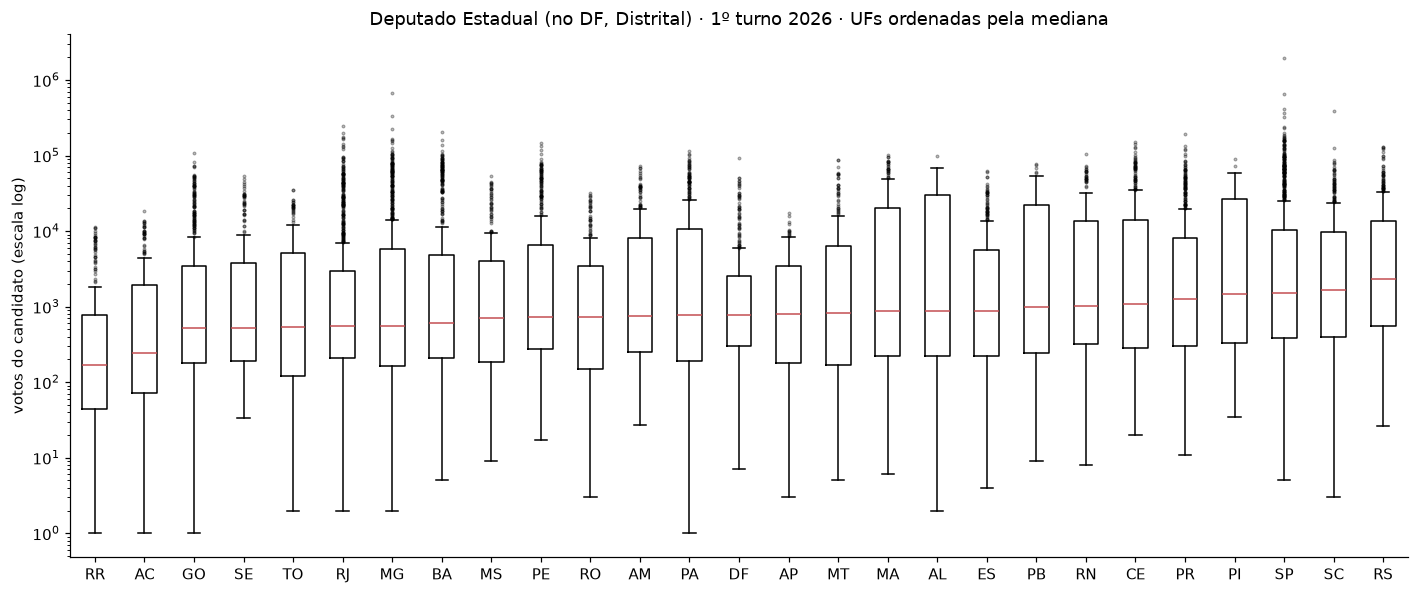

    candidatos  mediana    media
uf                              
RR         229    168.0   1359.0
AC         218    242.0   2035.0
GO         554    517.0   6162.0
SP        1277   1525.0  17068.0
SC         395   1658.0  10265.0
RS         519   2337.0  11123.0


In [22]:
de = val[val["cargo"] == "deputado_estadual"]
ordem = de.groupby("uf")["votos"].median().sort_values().index

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.boxplot([de.loc[de["uf"] == uf, "votos"].clip(lower=1) for uf in ordem], tick_labels=ordem,
           flierprops={"marker": ".", "markersize": 3, "alpha": 0.4}, medianprops={"color": "#C44E52"})
ax.set_yscale("log")
ax.set_ylabel("votos do candidato (escala log)")
ax.set_title("Deputado Estadual (no DF, Distrital) · 1º turno 2026 · UFs ordenadas pela mediana")
plt.tight_layout()
plt.savefig(FIGS / "grafico_deputado_estadual.png", bbox_inches="tight")
plt.show()

print(de.groupby("uf")["votos"].agg(candidatos="size", mediana="median", media="mean")
        .loc[ordem[[0, 1, 2, -3, -2, -1]]].round(0).to_string())

**Leitura dos gráficos e da tabela-resumo.**

- **Presidente:** Flávio Bolsonaro (47,03%) e Lula (45,16%) vão ao 2º turno, separados por 2,2 milhões de votos. Os três seguintes (Cury, Renan Santos e Caiado) ficam entre 2,2% e 2,9%. Os outros sete somam menos de 0,5%.
- **Senador:** o PL elegeu 19 das 54 cadeiras, mais que MDB (7) e PT (6) juntos. A moda, aqui, é o PL.
- **Deputado Federal:** a média (15.636) é **12 vezes** a mediana (1.270), e o CV passa de 400%. A média não representa o candidato típico. O histograma é **bimodal** em escala log: um grande grupo com centenas ou poucos milhares de votos e um segundo pico perto de 100 mil, que são os candidatos competitivos. O limite de Tukey (15.582) cai quase em cima do eleito com menos votos (13.732): **502 dos 505 eleitos são "outliers"** pela regra, ao lado de 690 não eleitos. É o melhor exemplo do slide *outlier não é erro*. Remover esses valores seria apagar justamente quem foi eleito.
- **Deputado Estadual:** o mesmo padrão em todas as UFs (caixas longas e muitos outliers só para cima). A mediana vai de 168 votos (RR) a 2.337 (RS). UFs com eleitorado pequeno e muitos candidatos por vaga têm mediana baixa. Comparar médias entre UFs aqui seria enganoso, porque cada UF tem eleitorado e número de candidatos diferentes.
- **Em todos os cargos, média/mediana > 5:** pela tabela do slide de resumo, a medida certa é a **mediana com IQR**.

## PCA · perfil de votação das 27 UFs para Presidente

Os 5 passos da aula:

1. **Matriz**: linhas = 27 UFs, colunas = % dos votos válidos dos candidatos com pelo menos 1% no país (a mesma `X` da correlação);
2. **Padronizar** cada coluna (z-score);
3. Ajustar o PCA e ler a **variância explicada**;
4. Escolher **k**;
5. Interpretar os **loadings** e plotar PC1 × PC2.

In [23]:
Z = StandardScaler().fit_transform(X)
pca = PCA().fit(Z)

variancia = pd.DataFrame({
    "variância_explicada_%": 100 * pca.explained_variance_ratio_,
    "acumulada_%": 100 * pca.explained_variance_ratio_.cumsum(),
    "autovalor": pca.explained_variance_,
}, index=[f"PC{i+1}" for i in range(pca.n_components_)])
print(variancia.round(2).to_string())

# para comparação: sem padronizar
pca_bruto = PCA().fit(X)
print("\nSem padronizar, PC1 explicaria:", f"{100*pca_bruto.explained_variance_ratio_[0]:.1f}%",
      "(dominado pelas colunas de maior variância, Lula e Flávio)")

     variância_explicada_%  acumulada_%  autovalor
PC1                  50.55        50.55       2.62
PC2                  31.62        82.17       1.64
PC3                  12.35        94.52       0.64
PC4                   5.48       100.00       0.28
PC5                   0.00       100.00       0.00

Sem padronizar, PC1 explicaria: 98.3% (dominado pelas colunas de maior variância, Lula e Flávio)


In [24]:
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])
loadings.to_csv(DADOS / "pca_loadings.csv")

scores = pd.DataFrame(pca.transform(Z)[:, :2], index=X.index, columns=["PC1", "PC2"])
scores.join(X).round(2).to_csv(DADOS / "pca_scores_ufs.csv")
loadings.round(3)

,PC1,PC2,PC3
Flávio Bolsonaro,-0.580,-0.168,-0.407
Ronaldo Caiado,-0.150,-0.620,0.718
Lula,0.593,0.210,0.242
Augusto Cury,-0.238,0.661,0.282
Renan Santos,-0.483,0.327,0.425


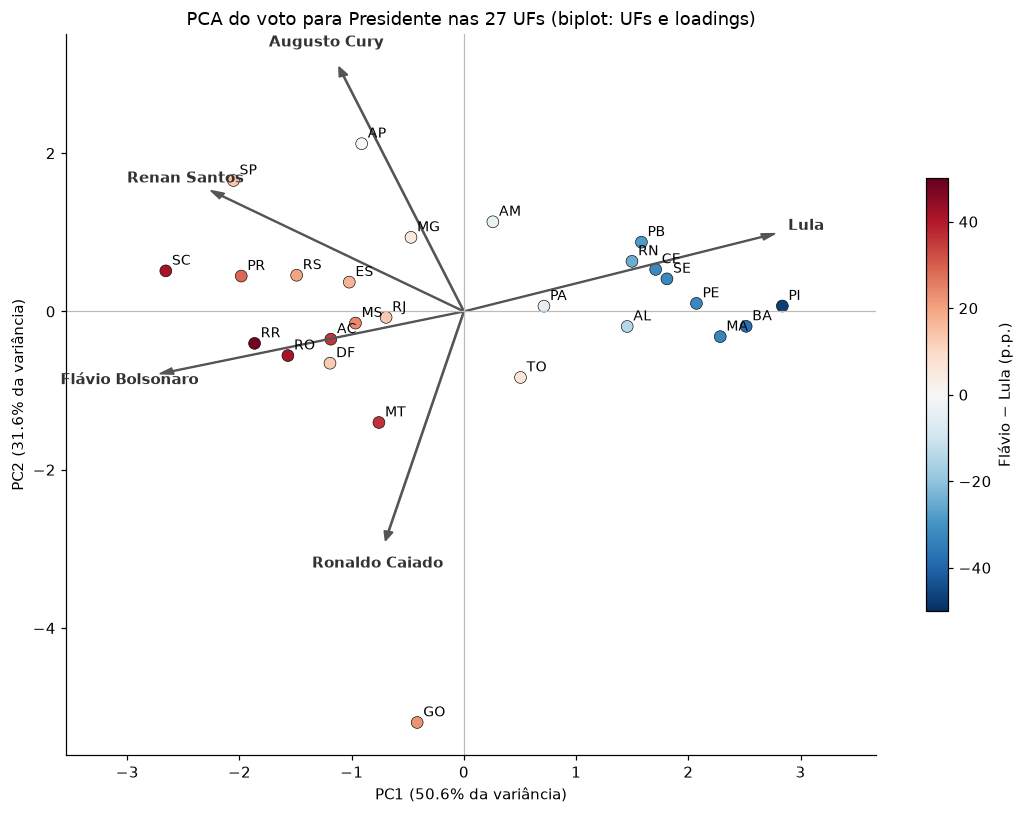

In [25]:
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.axhline(0, color="#BBBBBB", lw=0.8)
ax.axvline(0, color="#BBBBBB", lw=0.8)
margem = X["Flávio Bolsonaro"] - X["Lula"]
pontos = ax.scatter(scores["PC1"], scores["PC2"], c=margem, cmap="RdBu_r", vmin=-50, vmax=50,
                    s=60, edgecolor="black", lw=0.4)
fig.colorbar(pontos, ax=ax, shrink=0.6, label="Flávio − Lula (p.p.)")
for uf, (x, y) in scores.iterrows():
    ax.annotate(uf, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=9)

escala = 0.9 * np.abs(scores.values).max()
for nome, (lx, ly) in loadings[["PC1", "PC2"]].iterrows():
    ax.arrow(0, 0, lx * escala, ly * escala, color="#555555", width=0.01, head_width=0.08, length_includes_head=True)
    ax.text(lx * escala * 1.1, ly * escala * 1.1, nome, color="#333333", fontsize=10, fontweight="bold",
            ha="center", va="center")

ev = 100 * pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({ev[0]:.1f}% da variância)")
ax.set_ylabel(f"PC2 ({ev[1]:.1f}% da variância)")
ax.margins(x=0.15)
ax.set_title("PCA do voto para Presidente nas 27 UFs (biplot: UFs e loadings)")
plt.tight_layout()
plt.savefig(FIGS / "pca_presidente_ufs.png", bbox_inches="tight")
plt.show()

In [26]:
print("UFs nos extremos de cada componente:")
for pc in ["PC1", "PC2"]:
    s = scores[pc].sort_values()
    print(f"  {pc}  menor: {', '.join(s.index[:4])}   |   maior: {', '.join(s.index[-4:])}")
print()
print(scores.join(X).sort_values("PC1").round(2).to_string())

UFs nos extremos de cada componente:
  PC1  menor: SC, SP, PR, RR   |   maior: PE, MA, BA, PI
  PC2  menor: GO, MT, TO, DF   |   maior: MG, AM, SP, AP

     PC1   PC2  Flávio Bolsonaro  Ronaldo Caiado   Lula  Augusto Cury  Renan Santos
uf                                                                                 
SC -2.66  0.51             66.65            1.78  25.04          2.98          2.95
SP -2.05  1.65             51.93            2.33  38.20          3.59          3.23
PR -1.98  0.45             59.91            2.60  31.20          3.11          2.69
RR -1.87 -0.40             71.06            1.12  22.86          2.64          2.03
RO -1.57 -0.56             67.45            1.75  25.89          2.61          1.98
RS -1.49  0.46             55.64            2.47  35.73          3.04          2.61
DF -1.19 -0.65             51.31            4.80  38.11          2.59          2.64
AC -1.19 -0.35             64.56            1.83  28.73          2.88          1.70
ES -1.02

**Leitura do PCA.**

**Quantos componentes?** PC1 explica 50,6% e PC2 31,6%: juntos, **82,2%**, dentro da regra prática de 80–90%. Ficamos com **k = 2**. O PC5 tem variância zero porque as 5 colunas são percentuais que somam quase 100%: conhecendo quatro, a quinta está determinada. É o mesmo efeito do −0,99 entre Flávio e Lula.

**Sem padronizar**, o PC1 explicaria 98,3% e só repetiria a escala: o desvio padrão de Flávio e Lula entre as UFs é de cerca de 14 p.p., e o dos outros três é de no máximo 2,2 p.p. É o caso do slide de padronização: sem z-score, o PCA só enxerga quem tem mais variância.

**Loadings**

| Componente | Lado negativo | Lado positivo | Leitura |
|---|---|---|---|
| **PC1** (50,6%) | Flávio (−0,58), Renan Santos (−0,48), Cury (−0,24) | **Lula (+0,59)** | Eixo **Lula × oposição**. Positivo: SE, MA, BA, PI, PE, CE, PB, RN, AL (Nordeste). Negativo: SC, SP, PR, RR, RO, RS. |
| **PC2** (31,6%) | **Caiado (−0,62)** | **Cury (+0,66)**, Renan (+0,33) | Eixo da **terceira via**: voto em Caiado × voto em Cury/Renan. GO fica isolado em −5,2, porque concentra o voto em Caiado. No outro extremo estão AP, SP, AM e MG, onde Cury e Renan foram melhor. |

No biplot, cada seta mostra para onde cresce o voto de um candidato, e a cor de cada UF é a margem Flávio − Lula. O PC1 recupera praticamente essa margem: as UFs vermelhas ficam à esquerda e as azuis à direita. O mapa político do 1º turno é, sobretudo, Nordeste × Sul/Centro-Oeste/Norte.

**Cuidado:** o PC2 é, em boa parte, **um único estado**. Com só 27 observações, o PCA é sensível a outliers (como avisa o slide), e Goiás sozinho define uma direção. Um PCA sem GO, ou com dados por município, daria um PC2 diferente.

## Limites e cuidados

Os dados vêm da fonte primária (TSE) e conferem exatamente com os totais oficiais, mas são um **retrato de 16/10/2026**: sete UFs (AM, DF, MG, PI, RJ, RO e SC) foram retotalizadas entre 10 e 15/10 por decisões sobre candidaturas *sub judice*, e uma nova coleta pode trazer outros números. Os votos anulados ficaram fora das análises. No Senador, cada eleitor deu dois votos, então os percentuais são sobre votos, não sobre eleitores. Votos absolutos não se comparam entre UFs (o eleitorado de SP é 85 vezes o de RR), por isso a correlação e o PCA usam percentuais. Ainda assim, essas análises têm só 27 observações, são **entre UFs** e não sobre eleitores (falácia ecológica), não provam causa, e o PCA, linear e sensível a outliers, teve o PC2 definido quase só por Goiás. Por fim, 1,5 × IQR é convenção: aqui ela marca como outlier quase todos os eleitos, que são votos reais, não erros.

### Arquivos entregues

| Arquivo | Conteúdo |
|---|---|
| `dados/presidente_1t.csv` | candidatos a Presidente no Brasil (BR), no exterior (ZZ) e nas 27 UFs |
| `dados/senador_1t.csv` | candidatos a Senador nas 27 UFs |
| `dados/deputado_federal_1t.csv` | candidatos a Deputado Federal nas 27 UFs |
| `dados/deputado_estadual_1t.csv` | candidatos a Deputado Estadual (26 UFs) e Distrital (DF) |
| `dados/totais_por_uf_1t.csv` | eleitorado, comparecimento, brancos, nulos e votos nominais por cargo e UF |
| `dados/resumo_estatistico_por_cargo.csv` | média, mediana, desvio, CV, quartis, IQR e outliers |
| `dados/pca_loadings.csv`, `dados/pca_scores_ufs.csv` | resultado do PCA |
| `dados/log_coleta_*.csv` | URL, status e horário de cada download |
| `figuras/*.png` | um gráfico por cargo, correlação e PCA |
| `cache/*.json` | respostas originais do TSE |

Fonte: Tribunal Superior Eleitoral, resultados.tse.jus.br. Eleições 6257 (federal) e 6259 (estadual), 1º turno de 04/10/2026.